# Day 4 — Image Captioning with BLIP-2

**Module 5: VLMs — VQA, Captioning & Multimodal Embeddings**

Today I will generate natural-language captions for images and inspect how captions can make image collections searchable. I will use a pretrained BLIP-2 model to produce captions, compare a general caption with a question-guided caption, and save the results.

**What I will do**
- Understand image captioning and how it differs from VQA.
- Load a pretrained BLIP-2 captioning model.
- Generate captions for uploaded images.
- Try question-guided captioning.
- Save captions and image metadata in JSON.
- Discuss when captions (searchable text) are useful and when image embeddings are more appropriate.

**Important:** Captions can omit details or hallucinate. Inspect each caption against the image.


### 2. Install dependencies

In [1]:
!pip -q install -U transformers accelerate pillow

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


### 3. Upload images to caption

Upload one or more images (JPG/PNG). Choose varied examples if possible: a natural scene, an object/product, and a document or chart. Avoid sensitive/private images.

Saving Bright Kitchen Countertop Still Life.png to Bright Kitchen Countertop Still Life.png
Bright Kitchen Countertop Still Life.png (1536, 1024)


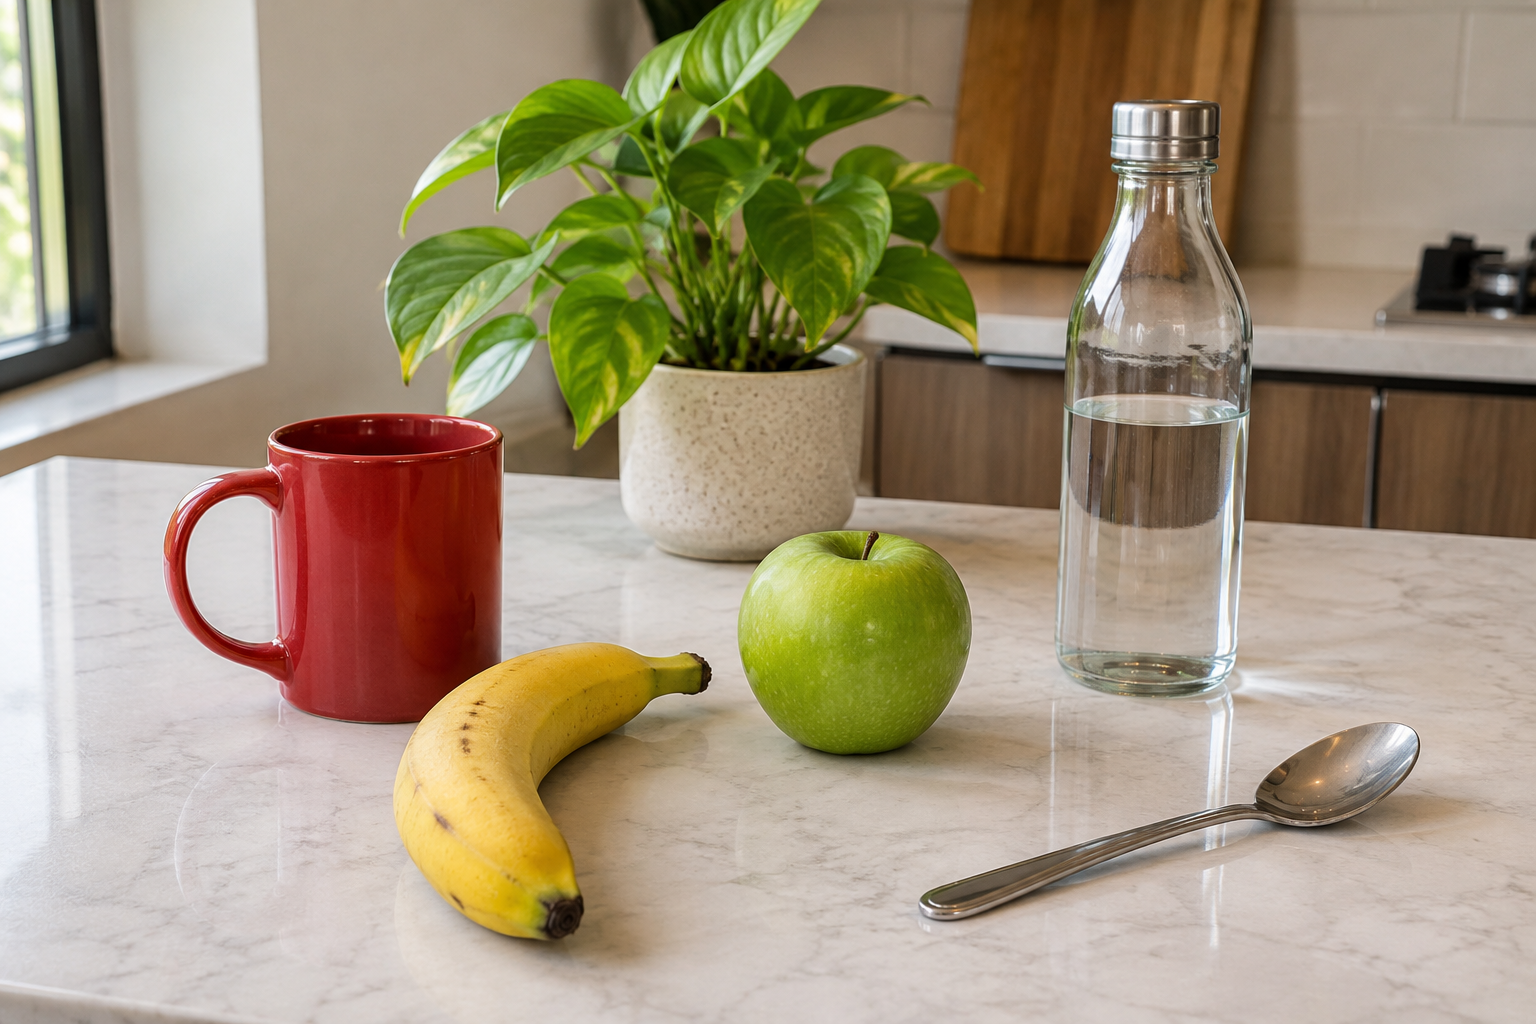

In [2]:
from google.colab import files
from PIL import Image
from IPython.display import display
from pathlib import Path

uploaded = files.upload()
if not uploaded:
    raise ValueError("Upload at least one image.")

image_paths = list(uploaded.keys())
images = []

for path in image_paths:
    img = Image.open(path).convert("RGB")
    images.append(img)
    print(path, img.size)
    display(img)


### 4. Load the pretrained BLIP-2 model

BLIP-2 connects a vision encoder to a language model through a lightweight querying transformer. The selected checkpoint uses an OPT language model. Loading may take time and memory.

Model: [Salesforce/blip2-opt-2.7b](https://huggingface.co/Salesforce/blip2-opt-2.7b)


In [4]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.14.1+cpu
CUDA available: False


In [5]:
from transformers import Blip2Processor, Blip2ForConditionalGeneration

MODEL_ID = "Salesforce/blip2-opt-2.7b"

processor = Blip2Processor.from_pretrained(MODEL_ID)
caption_model = Blip2ForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto"
)

print("Loaded:", MODEL_ID)


model.safetensors.index.json:   0%|          | 0.00/122k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/1247 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/accelerate/utils/modeling.py:1598: UserWarning: The following device_map keys do not match any submodules in the model: ['query_tokens']
  warnings.warn(


Loaded: Salesforce/blip2-opt-2.7b


### 5. Generate a general caption

A general caption describes the main content of an image in a short sentence. The model may not mention every object or detail.

In [6]:
def generate_caption(pil_image, prompt=None, max_new_tokens=80):
    inputs = processor(
        images=pil_image,
        text=prompt,
        return_tensors="pt"
    )

    inputs = {k: v.to(caption_model.device) for k, v in inputs.items()}

    with torch.inference_mode():
        generated_ids = caption_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens
        )

    return processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )[0].strip()

captions = []

for path, img in zip(image_paths, images):
    caption = generate_caption(img)
    captions.append({
        "image_filename": Path(path).name,
        "caption": caption
    })
    print("\nImage:", path)
    print("Caption:", caption)



Image: Bright Kitchen Countertop Still Life.png
Caption: a white marble counter top


### 6. Try question-guided captioning

Instead of asking for a generic caption, provide a prompt that directs attention to a particular aspect. This is related to VQA: the answer is guided by a question or instruction.

In [7]:
guided_prompt = "Describe the main objects and their visible actions or attributes."

guided_captions = []
for path, img in zip(image_paths, images):
    caption = generate_caption(img, prompt=guided_prompt, max_new_tokens=100)
    guided_captions.append({
        "image_filename": Path(path).name,
        "prompt": guided_prompt,
        "caption": caption
    })
    print("\nImage:", path)
    print("Guided caption:", caption)



Image: Bright Kitchen Countertop Still Life.png
Guided caption: Describe the main objects and their visible actions or attributes.


### 7. Compare general and guided captions

Inspect whether the guided prompt changed the level of detail. More words do not necessarily mean a more accurate caption.

In [8]:
for general, guided in zip(captions, guided_captions):
    print("=" * 80)
    print("IMAGE:", general["image_filename"])
    print("GENERAL:", general["caption"])
    print("GUIDED: ", guided["caption"])


IMAGE: Bright Kitchen Countertop Still Life.png
GENERAL: a white marble counter top
GUIDED:  Describe the main objects and their visible actions or attributes.


### 8. Caption as text index vs raw image representation

A caption converts visual content into words. This is useful when:
- Users search with natural-language keywords.
- You want a human-readable summary for each image.
- You want to index image descriptions in a text search system.

However, captions are lossy: they may omit small objects, exact colors, text, spatial relationships, or details not emphasized by the captioner.

An image embedding preserves a dense numerical representation of visual content and can support similarity search without requiring every detail to be expressed in a caption. Day 5 will use CLIP to embed images and text in a shared space.

A practical system may store both:
- Caption text for readable keyword/search indexing.
- Image embedding for visual-semantic similarity retrieval.


### 9. Save captions and metadata

This writes the generated captions to JSON. It does not save model weights or copy the uploaded images.

In [9]:
import json
from datetime import datetime

caption_record = {
    "module": 5,
    "day": 4,
    "model": MODEL_ID,
    "images": [
        {
            "image_filename": general["image_filename"],
            "general_caption": general["caption"],
            "guided_prompt": guided["prompt"],
            "guided_caption": guided["caption"]
        }
        for general, guided in zip(captions, guided_captions)
    ],
    "created_at": datetime.now().isoformat(timespec="seconds")
}

output_path = Path("day4_image_captions.json")
output_path.write_text(
    json.dumps(caption_record, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("Saved:", output_path.resolve())


Saved: /content/day4_image_captions.json
